<a href="https://colab.research.google.com/github/ejcastrof/telecom-analysis/blob/main/S7_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:


# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)



plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico de valores nulos**

**users**
- `churn_date` (88.35%): conservar sin imputar; el nulo significa que el cliente sigue activo, no es un dato faltante.
- `city` (11.73%): investigar y dejar como "Unknown"; imputar inventaría ciudades y sesgaría la segmentación.
- Resto de columnas (0 nulos): sin acción, están completas.

**usage**
- `duration` (55.19%): dejar como nulo; solo aplica a llamadas, imputar distorsionaría el promedio.
- `length` (44.74%): dejar como nulo; solo aplica a mensajes, es un nulo estructural.
- Inconsistencias duration/length (28 filas, 0.07%): marcarlas y revisarlas en la limpieza; 12 llamadas con `length` y 16 mensajes con `duration` pueden ser errores de registro.
- `date` (0.13%): dejar como nulo o eliminar esas 50 filas; es menos del 5% y no se puede inventar la fecha.
- Resto de columnas (0 nulos): sin acción, están completas.

**plans**
- Sin nulos: no requiere exploración adicional, es un catálogo pequeño y completo.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` va de 10,000 a 13,999 con 4,000 registros y sin valores raros; es solo un identificador y no requiere acción.
- La columna `age` tiene un mínimo de -999, que es un sentinel (una edad negativa es imposible); el resto de la distribución es razonable (percentil 25 = 32, mediana = 47, máximo = 79). Ese valor arrastra el promedio hacia abajo (33.7 frente a una mediana de 47) e infla la desviación estándar (123), así que hay que reemplazarlo por nulo en la limpieza.

In [ ]:

# explorar columnas numéricas de usage
usage.describe()



,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` no muestran valores raros: `id` va de 1 a 40,000 y `user_id` de 10,000 a 13,999, el mismo rango que en `users`.
- La columna `duration` tiene mínimo 0, máximo 120 y mediana 3.5; el 75% de las llamadas dura menos de 7 minutos, así que el máximo de 120 es un valor atípico muy lejano que hay que revisar, y los 0 pueden ser llamadas sin contestar o registros dudosos.
- La columna `length` tiene mínimo 0, máximo 1,490 y mediana 50; el 75% de los mensajes tiene 64 caracteres o menos, así que 1,490 es un valor extremo (posible error de registro) y los 0 corresponden a mensajes vacíos que hay que revisar.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(col)
    print(users[col].unique())
    print()


city
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

plan
['Basico' 'Premium']



- La columna `city` contiene 96 registros (2.4%) con el valor "?", un sentinel que no es una ciudad real, además de los 469 nulos; en total hay 565 ciudades desconocidas (14.1%). También mezcla ciudades de Colombia (Medellín, Bogotá, Cali) con ciudades de México escritas como abreviaturas (CDMX, GDL, MTY). Acción: reemplazar "?" por nulo/"Unknown" y, si se necesita, crear una columna de país.
- La columna `plan` solo tiene dos valores, "Basico" y "Premium", sin variantes de escritura ni valores raros; no requiere limpieza.

In [ ]:
# explorar columna categórica de usage
usage['type'].unique()

array(['call', 'text'], dtype=object)

- La columna `type` solo contiene "call" y "text", que son los dos tipos de evento esperados; no requiere limpieza.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
**Diagnóstico de valores inválidos o sentinels**

**¿En qué columnas encontraste valores inválidos o sentinels?**
- `users['age']`: 55 registros (1.4%) con el valor -999, un sentinel; una edad negativa es imposible y distorsiona el promedio (33.7 frente a una mediana de 47) y la desviación estándar (123).
- `users['city']`: 96 registros (2.4%) con el valor "?", que no es una ciudad real; sumados a los 469 nulos hay 565 ciudades desconocidas (14.1%).
- `usage['duration']` y `usage['length']`: no tienen sentinels claros (no hay -999 ni 999), pero sí valores a revisar: ceros en ambas columnas, un máximo de 120 en `duration` y de 1,490 en `length`, muy por encima del percentil 75 (7 y 64). Además hay 28 filas inconsistentes (12 llamadas con `length` y 16 mensajes con `duration`).
- `users['plan']`, `usage['type']`, `user_id` e `id`: sin valores inválidos.

**¿Qué acción tomarías?**
- `age = -999`: reemplazar por nulo (NaN) y no imputar todavía; es un código de "dato no disponible", no una edad real.
- `city = "?"`: reemplazar por nulo y luego unificar con los nulos existentes como "Unknown", para no inventar ciudades.
- `duration` y `length` con ceros y extremos: no eliminar ni reemplazar por ahora; analizarlos con IQR y boxplots en el paso 5 para decidir si son errores u outliers válidos.
- Las 28 filas inconsistentes: marcarlas como posibles errores de registro y revisarlas en la limpieza, sin eliminarlas todavía.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


- En `reg_date`, los clientes se registraron entre 2022 y 2024 con una distribución pareja (alrededor de 1,300 por año), pero aparecen 40 registros (1%) con año 2026, una fecha futura imposible porque los datos llegan hasta 2024.


In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts().sort_index())


2024.0    39950
Name: date, dtype: int64


- En `date`, todos los registros con fecha válida son de 2024 (39,950), sin años fuera de rango; los 50 restantes son los nulos ya identificados.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  

- ¿Aparecen años imposibles? Sí, en `reg_date`: 40 registros (1%) con año 2026, posterior al cierre de los datos en 2024. En `date` no hay años imposibles, todo es de 2024.
- ¿Qué haría con ellas? Reemplazar esas 40 fechas por nulo (NaT) y conservar las filas; no las eliminaría porque el resto de los datos del cliente sí sirve, y no inventaría un año de reemplazo porque no sabemos cuál era el correcto. También agregaría una marca (flag) para poder revisarlos.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print((users['city'] == '?').sum())
print(users['city'].isna().sum())


0
565


In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR (Missing At Random) para duration
print(usage['duration'].isna().groupby(usage['type']).mean())

type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [ ]:
# Verificación MAR (Missing At Random) para Length
print(usage['length'].isna().groupby(usage['type']).mean())


type
call    0.99933
text    0.00000
Name: length, dtype: float64


**Diagnóstico de nulos en `duration` y `length`**
- `duration`: 0% de nulos en las llamadas (`call`) y 99.93% en los mensajes (`text`); los nulos dependen de `type`, porque un mensaje no tiene duración. Es MAR (depende de otra columna observada).
- `length`: 99.93% de nulos en las llamadas (`call`) y 0% en los mensajes (`text`); también dependen de `type`, porque una llamada no tiene longitud. Es MAR.
- Decisión: dejarlos como nulos en ambas columnas. Imputarlos inventaría duraciones para mensajes y longitudes para llamadas, y distorsionaría los promedios; los nulos ya tienen una explicación clara.
- Las 28 filas inconsistentes (12 llamadas con `length` y 16 mensajes con `duration`, el 0.07% restante) se mantienen marcadas como posibles errores de registro.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({"is_text": "sum", "is_call": "sum", "duration": "sum"}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text": "cant_mensajes", "is_call": "cant_llamadas", "duration": "cant_minutos_llamada"})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True).mul(100).round(2))


Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

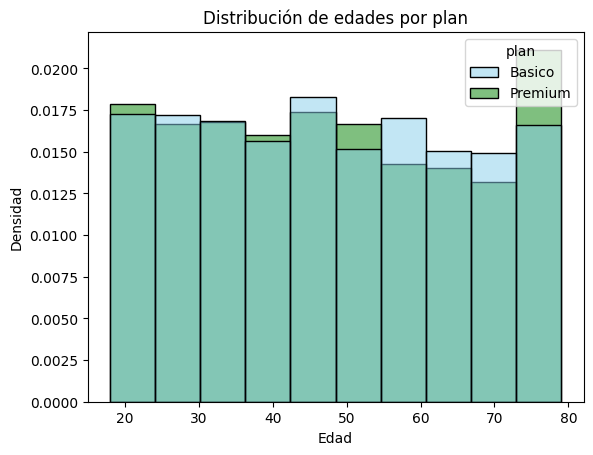

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], bins=10, stat='density', common_norm=False)
plt.title('Distribución de edades por plan')
plt.xlabel('Edad')
plt.ylabel('Densidad')
plt.show()

💡 Insights:
- Distribución: casi uniforme (plana) entre 18 y 79 años, con densidades similares en todos los rangos; no es simétrica ni sesgada de forma clara.
- Los dos planes siguen el mismo patrón; la única diferencia visible es que Premium concentra proporcionalmente más usuarios entre 70 y 79 años, mientras Básico es un poco mayor entre 55 y 62.
- No existe un segmento de edad claramente asociado a un plan.

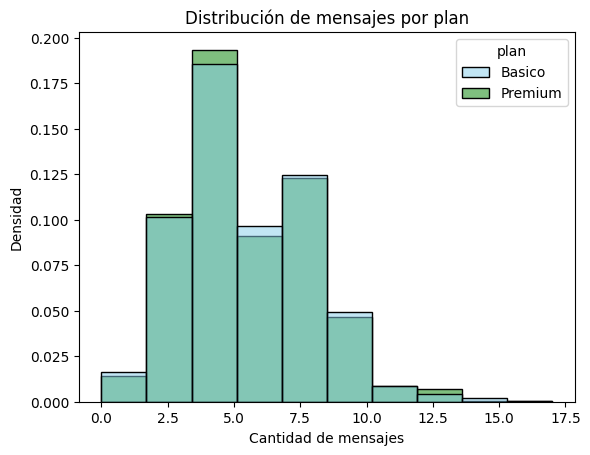

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], bins=10, stat='density', common_norm=False)
plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Densidad')
plt.show()


💡 Insights:
- Distribución: sesgada a la derecha; la mayoría envía entre 2 y 9 mensajes, con el pico en 3.5-5 mensajes y una cola larga que llega hasta cerca de 17.
- Las densidades de Básico y Premium casi se superponen por completo; Premium tiene una proporción apenas mayor en el pico (3.5-5), lo cual no representa una diferencia real de uso.
- Los usuarios con más de 12 mensajes son pocos y conviene revisarlos como posibles atípicos.

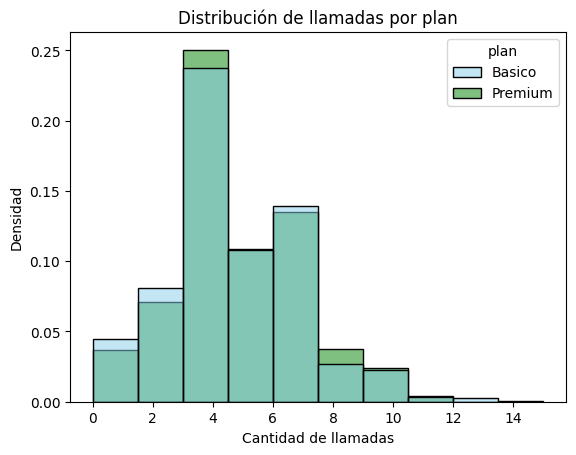

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], bins=10, stat='density', common_norm=False)
plt.title('Distribución de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Densidad')
plt.show()


💡 Insights:
- Distribución: sesgada a la derecha; la mayoría realiza entre 2 y 8 llamadas, con el pico en 3-5 llamadas y una cola que llega a cerca de 15.
- Los dos planes comparten la misma forma; Premium tiene una proporción ligeramente mayor en 3-5 y 7-9 llamadas, y Básico en 0-3, pero las diferencias son pequeñas.
- No hay evidencia de que los usuarios Premium llamen más que los Básico.

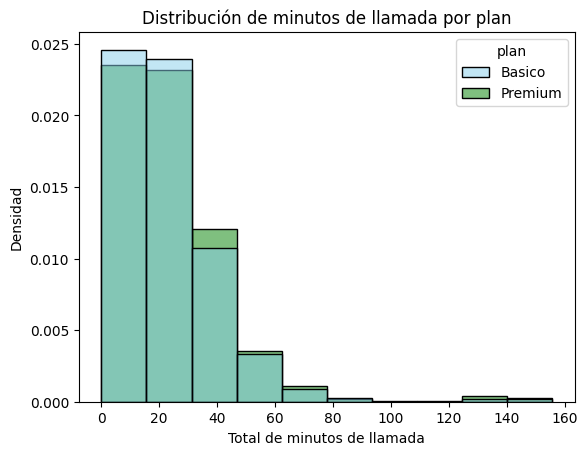

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], bins=10, stat='density', common_norm=False)
plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Total de minutos de llamada')
plt.ylabel('Densidad')
plt.show()


💡 Insights:
- Distribución: muy sesgada a la derecha; la gran mayoría acumula menos de 45 minutos, con el mayor número de usuarios entre 0 y 30 minutos.
- Los dos planes tienen la misma forma; Premium tiene una proporción algo mayor en 30-45 minutos y se aprecia un pequeño grupo de usuarios con más de 120 minutos, muy alejado del resto.
- Ese grupo sugiere outliers (uso excepcional, posible error de registro o fraude) y se analizará con boxplots en el siguiente paso.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

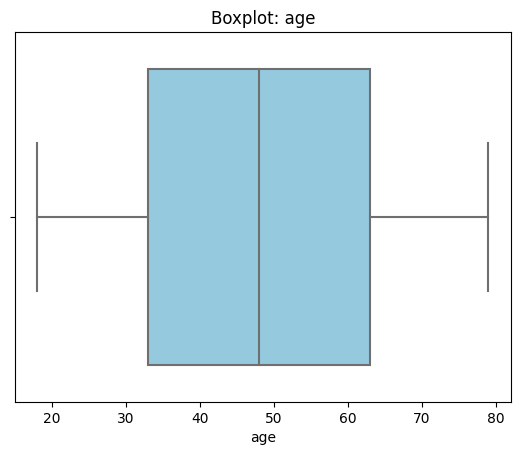

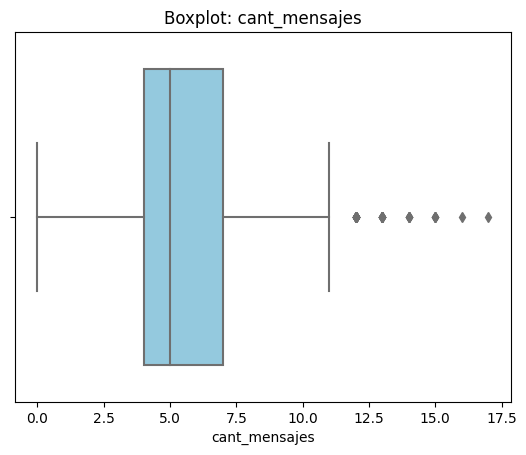

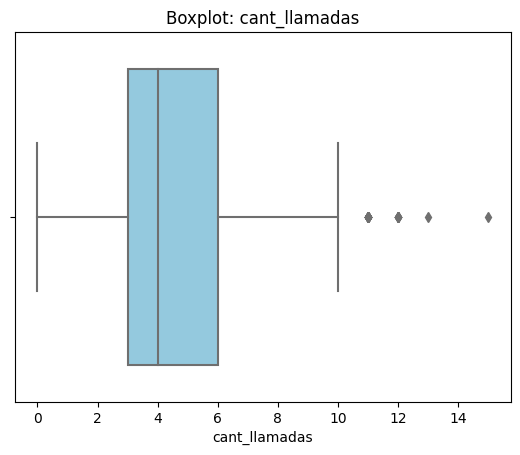

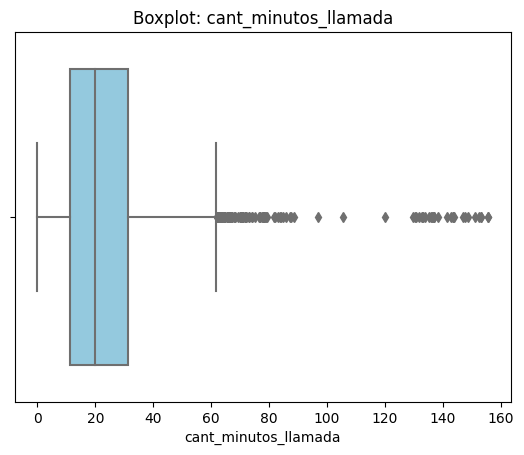

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡 Insights:
- Age: no presenta outliers; los bigotes cubren todo el rango de 18 a 79 años y la mediana (48) queda centrada en la caja, con una distribución simétrica.
- cant_mensajes: sí presenta outliers, solo del lado superior; la mediana es 5 y aparecen puntos desde 12 hasta 17 mensajes.
- cant_llamadas: sí presenta outliers, solo del lado superior; la mediana es 4 y aparecen puntos desde 11 hasta 15 llamadas.
- cant_minutos_llamada: sí presenta muchos outliers del lado superior; la mediana es cerca de 20 minutos y los puntos van desde 62 hasta 156, con un grupo claramente separado alrededor de 130-156 minutos.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(col)
    print("Límite superior:", limite_superior)
    print("Outliers:", n_outliers)
    print()



cant_mensajes
Límite superior: 11.5
Outliers: 46

cant_llamadas
Límite superior: 10.5
Outliers: 30

cant_minutos_llamada
Límite superior: 61.8575
Outliers: 109



In [ ]:
# Revisa los límites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡 Insights:
- cant_mensajes: mantener los outliers (46 usuarios, 1.2%, límite superior de 11.5); el máximo es 17 mensajes, solo un poco por encima del límite, y es un uso plausible de un cliente muy activo, no un error.
- cant_llamadas: mantener los outliers (30 usuarios, 0.8%, límite superior de 10.5); el máximo es 15 llamadas, cercano al límite, y representa clientes de uso alto legítimo, útiles para segmentar.
- cant_minutos_llamada: mantener los outliers pero marcarlos para revisión (109 usuarios, 2.7%, límite superior de 61.86); el máximo es 155.69, más de 7 veces la mediana, y el grupo de más de 120 minutos puede ser uso excepcional o un error de registro, por lo que no se eliminan y se segmentan aparte.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'Bajo uso',
    np.where(
        (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'Uso medio',
        'Alto uso'
    )
)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


In [ ]:
user_profile.loc[user_profile['cant_llamadas'].isna(), 'grupo_uso'] = np.nan

In [ ]:
print(user_profile['grupo_uso'].value_counts())

Uso medio    2943
Bajo uso      778
Alto uso      278
Name: grupo_uso, dtype: int64


In [ ]:
print(pd.crosstab(user_profile['plan'], user_profile['grupo_uso'], normalize='index').mul(100).round(1))

grupo_uso  Alto uso  Bajo uso  Uso medio
plan                                    
Basico          7.1      19.7       73.1
Premium         6.6      18.9       74.4


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30, 'Joven',
    np.where(user_profile['age'] < 60, 'Adulto', 'Adulto Mayor')
)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [ ]:
print(user_profile['grupo_edad'].value_counts())

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [ ]:
print(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index').mul(100).round(1))

grupo_uso     Alto uso  Bajo uso  Uso medio
grupo_edad                                 
Adulto             7.6      18.0       74.4
Adulto Mayor       6.1      21.0       72.9
Joven              6.7      20.7       72.6


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

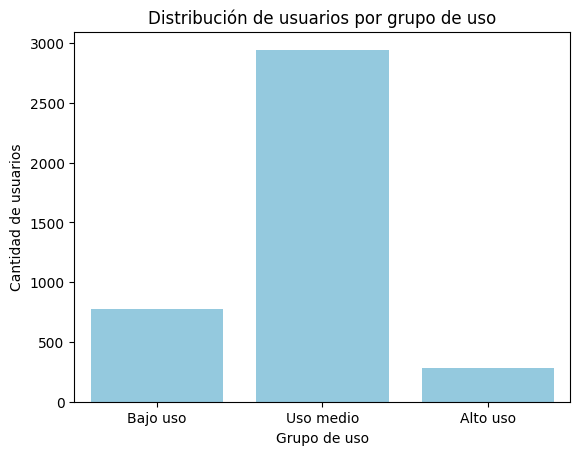

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

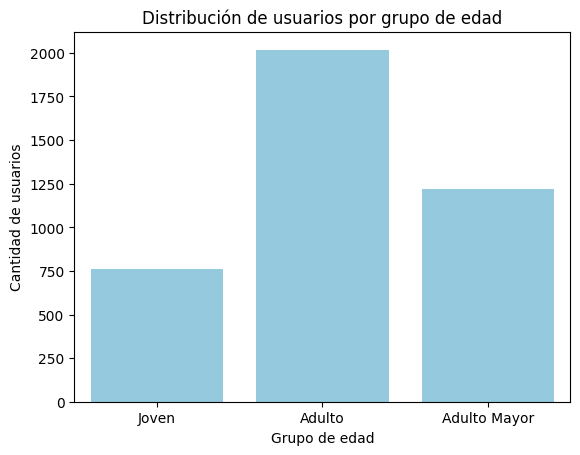

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='skyblue')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


In [ ]:
print(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index').mul(100).round(1))


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ Problemas detectados en los datos

- Edad (`age`): 55 clientes (1.4% de 4,000) tenían el valor -999, un código de dato faltante que distorsionaba el promedio (33.7 frente a 48.1 ya corregido); se reemplazó por la mediana.
- Ciudad (`city`): 96 registros (2.4%) con "?" y 469 nulos; en total 565 clientes (14.1%) sin ciudad conocida, lo que limita cualquier segmentación por ubicación o país.
- Fecha de registro (`reg_date`): 40 clientes (1.0%) con año 2026, imposible porque los datos llegan hasta 2024; se marcaron como nulos.
- Uso (`usage`): 28 filas (0.07%) inconsistentes (12 llamadas con longitud y 16 mensajes con duración) y 50 fechas nulas (0.13%); los nulos de `duration` (55.2%) y `length` (44.7%) no son errores, dependen del tipo de evento y se dejaron sin imputar.
- Fecha de baja (`churn_date`): 3,534 nulos (88.4%) que corresponden a clientes activos, no a datos faltantes.

🔍 Segmentos por Edad

- Adultos (30-59 años): 2,018 clientes, el 50.5% de la base y el segmento principal; son también los que más usan el servicio, con 7.6% en alto uso y solo 18.0% en bajo uso.
- Adultos mayores (60+): 1,222 clientes (30.6%); tienen el mayor porcentaje de bajo uso (21.0%) y el menor de alto uso (6.1%).
- Jóvenes (<30): 760 clientes (19.0%), el grupo más pequeño; con 20.7% en bajo uso y 6.7% en alto uso, su perfil es similar al de los adultos mayores.
- En los tres grupos el uso medio ronda el 73% y las diferencias entre edades son menores a 3 puntos porcentuales, por lo que la edad no es un factor determinante del nivel de uso.

📊 Segmentos por Nivel de Uso

- Uso medio: 2,943 clientes (73.6%), con menos de 10 llamadas y menos de 10 mensajes; es el núcleo de la base.
- Bajo uso: 778 clientes (19.5%), con menos de 5 llamadas y menos de 5 mensajes.
- Alto uso: 278 clientes (7.0%), con 10 o más llamadas o mensajes.
- El comportamiento es casi idéntico entre planes: Básico tiene 7.1% de alto uso y Premium 6.6%; el uso medio es 73.1% frente a 74.4%.

➡️ Esto sugiere que ni el plan contratado ni la edad explican de forma importante cuánto usa el cliente: el uso es parecido en todos los segmentos, por lo que la diferenciación de la oferta no debería basarse solo en el volumen de llamadas y mensajes.

Patrones de uso extremo (outliers)

- Mensajes: 46 clientes (1.2%) superan el límite de 11.5, con un máximo de 17; es uso alto plausible.
- Llamadas: 30 clientes (0.8%) superan el límite de 10.5, con un máximo de 15; también plausible.
- Minutos de llamada: 109 clientes (2.7%) superan 61.9 minutos, con un máximo de 155.7 (más de 7 veces la mediana de 19.8); hay un grupo separado por encima de 120 minutos que puede ser uso excepcional, error de registro o fraude.
- Decisión: se mantuvieron todos los outliers y se recomienda revisar el grupo de más de 120 minutos.

💡 Recomendaciones

- Revisar la propuesta de valor de Premium: como su uso es igual al de Básico, conviene diferenciarlo con beneficios distintos al volumen (por ejemplo, GB, servicio o precio por extra) o ajustar su precio.
- Diseñar una oferta específica para el segmento de alto uso (7%): son los clientes con mayor potencial de ingresos por excedentes, y conviene comparar su consumo con los límites incluidos en cada plan.
- Crear acciones de retención y activación para el segmento de bajo uso (19.5%), con un enfoque ligeramente mayor en adultos mayores y jóvenes (21.0% y 20.7%); validar el riesgo de abandono cruzándolo con `churn_date`.
- Poner alertas de monitoreo para los usuarios con más de 120 minutos de llamadas y revisar si son fraude o errores de registro.
- Mejorar la captura de datos: eliminar los códigos centinela (-999, "?"), validar fechas futuras y separar bien los campos de duración y longitud según el tipo de evento.
- Próximo paso: analizar el churn por segmento de uso y edad para priorizar las acciones.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`